# Markov Chain Model for Recovery test in Tomimoto and Satake 2026 
Following is the code for calculating inter-branch SNVs by the Markov chain model, and for model fitting by ABC-SMC. 

Here, we tested whether the framework can recover models and parameters, using data generated by simulations.

##### Packages information used in this code:  
numpy==2.0.1  
pyabc==0.12.15  
scipy==1.15.3  
seaborn==0.13.2  
matplotlib==3.10.0 

Artificial data generated by simulations must be saved in the /simulation_results directory.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm

import math
from scipy.stats import binom # structured elongation
from scipy.stats import hypergeom # stochastic elongation

import itertools # pattern of mutation expansion
import copy

### Transition matrices

In [2]:
# Elongation

def el_str_M(num_stem, mut_rate): # structured elongation transition matrix
    
    tr_matrix = np.zeros((num_stem+1, num_stem+1))
    
    for i in range(num_stem+1):
        for j in range(num_stem+1):
            
            tr_matrix[i, j] = binom.pmf(j-i, num_stem-i, mut_rate)

    return tr_matrix

def el_sto_M(num_stem, mut_rate): # stochastic elongation transition matrix
    
    tr_matrix = np.zeros((num_stem+1, num_stem+1))
    
    for i in range(num_stem+1):
        for j in range(num_stem+1):
            
            #print(sum([m for m in range(2*(num_stem-i)+1)]))
            tr_matrix[i, j] = sum([ binom.pmf(m, 2*(num_stem-i), mut_rate)
                                   *hypergeom.pmf(j, 2*num_stem, 2*i+m, num_stem) for m in range(2*(num_stem-i)+1)])

    return tr_matrix

In [3]:
# Branching

def br_wf_M(num_stem): # wright-fisher Branching transition matrix
    
    tr_matrix = np.zeros((num_stem+1, num_stem+1))
    
    for i in range(num_stem+1):
        for j in range(num_stem+1):

            tr_matrix[i, j] = binom.pmf(j, num_stem, i/num_stem)

    return tr_matrix

def br_sc_M(num_stem): # single cell Branching transition matrix
    
    tr_matrix = np.zeros((num_stem+1, num_stem+1))
    
    for i in range(num_stem+1):
        for j in range(num_stem+1):

            if j == 0:
                tr_matrix[i, j] = (num_stem-i)/num_stem
            elif j == num_stem:
                tr_matrix[i, j] = i/num_stem
            else:
                tr_matrix[i, j] = 0

    return tr_matrix

In [4]:
def state_V(num_stem): # state vector
    
    stateVector = np.zeros(num_stem+1, dtype=float) # state vectore
    stateVector[0] = 1
    
    return stateVector

def mat_pw(mat_, t_): # power of matrix
    
    return np.linalg.matrix_power(mat_, t_)

def initial_state(num_stem, i_): # state vector
    
    stateVector = np.zeros(num_stem+1, dtype=float) # state vectore
    stateVector[i_] = 1
    
    return stateVector

def inter_branch_f(mat_i, mat_j): # average distance 0325
    
    num_stem = len(mat_i)-1
    
    tes1 = mat_i
    tes2 = mat_j

    tes1_list = []
    tes2_list = []
    
    for i in range(num_stem+1):
        
        tes1_v = initial_state(num_stem, i)@tes1
        tes2_v = initial_state(num_stem, i)@tes2
        
        mean_1 = np.sum([kct*k for kct, k in enumerate(tes1_v)]) # mean of the state vector
        mean_2 = np.sum([kct*k for kct, k in enumerate(tes2_v)]) # --

        tes1_list.append(mean_1)
        tes2_list.append(mean_2)

    tes_list = []
    
    for j in range(num_stem+1):
    
        tes_list.append( tes1_list[j]/num_stem *(1-tes2_list[j]/num_stem) + (1-tes1_list[j]/num_stem)*tes2_list[j]/num_stem )
    
    return np.array(tes_list)

### Calculating inter-branch SNVs

In [5]:
# function: inter-branch mutation by Markov chain

def ibm_Markov(num_stem, mu_, div_, dyn_, brlist_): # 230222, 231105, 240208 
    """　Func for Exp. of Inter-branch mutations by Markov chain
    Args:
        num_stem    (int): Num of stem cells in meristem.
        mu_       (float): Rate of mutation per cell per meter
        div_      (float): Number of cell divisions per meter
        dyn_        (int): Dynamics of stem cells (1-> stru+unbias, 2-> stru+bias, 3-> stoc+unbias, 4-> stoc+bias)
        brlist_ (ndarray): List of branch length
    
    Return:
        [z_Flat, d_Flat, api_Flat] (list): Exp. of inter-branch mutation, Distance between branches, Apical states
    
    Note:
    """
    
    # given parameters
    numBranch = 7
    br_ID = ['11','10','21','20','31','30','40']

    µ_ = mu_ /div_

    s0_0 = round(brlist_[0] *div_)
    s0_1 = round(brlist_[1] *div_)
    s0_2 = round(brlist_[2] *div_)
    s0_3 = round(brlist_[3] *div_)

    b10_0 = round(brlist_[4] *div_)
    b10_1 = round(brlist_[5] *div_) 
    b11   = round(brlist_[6] *div_)

    b20_0 = round(brlist_[7] *div_)
    b20_1 = round(brlist_[8] *div_)
    b21   = round(brlist_[9] *div_)

    b30_0 = round(brlist_[10] *div_)
    b30_1 = round(brlist_[11] *div_)
    b31   = round(brlist_[12] *div_)
    
    brTimeMatrix = np.array([[0, b10_1+b11, b11+b10_0+s0_1+b20_0+b21, b11+b10_0+s0_1+b20_0+b20_1, b11+b10_0+s0_1+s0_2+b30_0+b31, b11+b10_0+s0_1+s0_2+b30_0+b30_1, s0_3+s0_2+s0_1+b10_0+b11],
                         [0,0, b10_1+b10_0+s0_1+b20_0+b21, b10_1+b10_0+s0_1+b20_0+b20_1, b10_1+b10_0+s0_1+s0_2+b30_0+b31, b10_1+b10_0+s0_1+s0_2+b30_0+b30_1, s0_3+s0_2+s0_1+b10_0+b10_1],
                         [0,0,0, b21+b20_1, b21+b20_0+s0_2+b30_0+b31, b21+b20_0+s0_2+b30_0+b30_1, s0_3+s0_2+b20_0+b21], 
                         [0,0,0,0, b20_1+b20_0+s0_2+b30_0+b31, b20_1+b20_0+s0_2+b30_0+b30_1, s0_3+s0_2+b20_0+b20_1], 
                         [0,0,0,0,0, b30_1+b31, s0_3+b30_0+b31],
                         [0,0,0,0,0,0, s0_3+b30_0+b30_1], 
                         [0,0,0,0,0,0,0]])

    #brTimeSet = sorted(set(brTimeMatrix.flatten())) # Set of lenght in order

    for kcut,k in enumerate(brTimeMatrix):
        for lcut,l in enumerate(brTimeMatrix):
            if kcut > lcut:
                brTimeMatrix[kcut][lcut]= l[kcut]

    # apical(0) non-apical(1) matrix
    api_M = np.array([[0, 0, 1, 1, 1, 1, 0],
                      [0, 0, 1, 1, 1, 1, 0],
                      [1, 1, 0, 0, 1, 1, 0],
                      [1, 1, 0, 0, 1, 1, 0],
                      [1, 1, 1, 1, 0, 0, 0],
                      [1, 1, 1, 1, 0, 0, 0],
                      [0, 0, 0, 0, 0, 0, 0]])
    
    # caululation of matrix ----------------------------------------------------------

    # transition matrix
    st_V = state_V(num_stem)

    if dyn_ == 1:
        el_Mat = el_str_M(num_stem, µ_) # structured
        br_Mat = br_wf_M(num_stem) # wright-fisher
        
    elif dyn_ == 2:
        el_Mat = el_str_M(num_stem, µ_) # structured
        br_Mat = br_sc_M(num_stem) # single cell
        
    elif dyn_ == 3:
        el_Mat = el_sto_M(num_stem, µ_) # stochastic
        br_Mat = br_wf_M(num_stem) # wright-fisher
        
    elif dyn_ == 4:
        el_Mat = el_sto_M(num_stem, µ_) # stochastic
        br_Mat = br_sc_M(num_stem) # single cell
    
    else:
        print("dyn_ is not defined")

    # matrix calculation -------------------------------------------------------------
    st_V_s0 = st_V @ mat_pw(el_Mat, s0_0)

    st_V_b10_0 = st_V_s0 @ br_Mat @ mat_pw(el_Mat, b10_0)
    st_V_b11 =  st_V_b10_0 @ br_Mat @ mat_pw(el_Mat, b11)
    st_V_b10 = st_V_b10_0 @ br_Mat @ mat_pw(el_Mat, b10_1) # 240208

    st_V_s1 = st_V_s0 @ br_Mat @ mat_pw(el_Mat, s0_1) # 240208

    st_V_b20_0 = st_V_s1 @ br_Mat @ mat_pw(el_Mat, b20_0)
    st_V_b21 = st_V_b20_0 @ br_Mat @ mat_pw(el_Mat, b21)
    st_V_b20 = st_V_b20_0 @ br_Mat @ mat_pw(el_Mat, b20_1) #240208

    st_V_s2 = st_V_s1 @ br_Mat @ mat_pw(el_Mat, s0_2) #250514

    st_V_b30_0 = st_V_s2 @ br_Mat @ mat_pw(el_Mat, b30_0)
    st_V_b31 = st_V_b30_0 @ br_Mat @ mat_pw(el_Mat, b31)
    st_V_b30 = st_V_b30_0 @ br_Mat @ mat_pw(el_Mat, b30_1) #230208

    st_V_b40 = st_V_s2 @ br_Mat @ mat_pw(el_Mat, s0_3) #230208

    # transitions after froking --------------------------------------------------------
    
    # branch 1 to
    af_11_10 = inter_branch_f(
        br_Mat @ mat_pw(el_Mat, b11), 
        br_Mat @ mat_pw(el_Mat, b10_1) ) #240208

    af_11_21 = inter_branch_f(
        br_Mat@mat_pw(el_Mat,b10_0)@br_Mat@mat_pw(el_Mat, b11),
        br_Mat@mat_pw(el_Mat, s0_1)@br_Mat@mat_pw(el_Mat, b20_0)@br_Mat@mat_pw(el_Mat, b21) ) #240208

    af_11_20 = inter_branch_f(
        br_Mat@mat_pw(el_Mat, b10_0)@br_Mat@mat_pw(el_Mat, b11),
        br_Mat@mat_pw(el_Mat, s0_1)@br_Mat@mat_pw(el_Mat, b20_0)@br_Mat@mat_pw(el_Mat, b20_1) ) #240208

    af_11_31 = inter_branch_f(
        br_Mat@mat_pw(el_Mat,b10_0)@br_Mat@mat_pw(el_Mat, b11),
        br_Mat@mat_pw(el_Mat, s0_1)@br_Mat@mat_pw(el_Mat, s0_2)@br_Mat@mat_pw(el_Mat, b30_0)@br_Mat@mat_pw(el_Mat, b31) ) #240208

    af_11_30 = inter_branch_f(
        br_Mat@mat_pw(el_Mat, b10_0)@br_Mat@mat_pw(el_Mat, b11),
        br_Mat@mat_pw(el_Mat, s0_1)@br_Mat@mat_pw(el_Mat, s0_2)@br_Mat@mat_pw(el_Mat, b30_0)@br_Mat@mat_pw(el_Mat, b30_1) ) #240208

    af_11_40 = inter_branch_f(
        br_Mat@mat_pw(el_Mat, b10_0)@br_Mat@mat_pw(el_Mat, b11),
        br_Mat@mat_pw(el_Mat, s0_1)@br_Mat@mat_pw(el_Mat, s0_2)@br_Mat@mat_pw(el_Mat, s0_3) ) #240208


    af_10_21 = inter_branch_f(
        br_Mat@mat_pw(el_Mat,b10_0)@br_Mat@mat_pw(el_Mat,b10_1), #240208
        br_Mat@mat_pw(el_Mat, s0_1)@br_Mat@mat_pw(el_Mat, b20_0)@br_Mat@mat_pw(el_Mat, b21) ) #240208

    af_10_20 = inter_branch_f( 
        br_Mat@mat_pw(el_Mat,b10_0)@br_Mat@mat_pw(el_Mat,b10_1), #240208
        br_Mat@mat_pw(el_Mat, s0_1)@br_Mat@mat_pw(el_Mat, b20_0)@br_Mat@mat_pw(el_Mat, b20_1) ) #240208

    af_10_31 = inter_branch_f( 
        br_Mat@mat_pw(el_Mat,b10_0)@br_Mat@mat_pw(el_Mat,b10_1), #240208
        br_Mat@mat_pw(el_Mat, s0_1)@br_Mat@mat_pw(el_Mat, s0_2)@br_Mat@mat_pw(el_Mat, b30_0)@br_Mat@mat_pw(el_Mat, b31) ) #240208

    af_10_30 = inter_branch_f( 
        br_Mat@mat_pw(el_Mat,b10_0)@br_Mat@mat_pw(el_Mat,b10_1), #240208
        br_Mat@mat_pw(el_Mat, s0_1)@br_Mat@mat_pw(el_Mat, s0_2)@br_Mat@mat_pw(el_Mat, b30_0)@br_Mat@mat_pw(el_Mat, b30_1) ) #240208

    af_10_40 = inter_branch_f( 
        br_Mat@mat_pw(el_Mat,b10_0)@br_Mat@mat_pw(el_Mat,b10_1), #240208
        br_Mat@mat_pw(el_Mat, s0_1)@br_Mat@mat_pw(el_Mat, s0_2)@br_Mat@mat_pw(el_Mat, s0_3) ) #240208

    # branch 2 to
    af_21_20 = inter_branch_f(
        br_Mat@mat_pw(el_Mat, b21),
        br_Mat@mat_pw(el_Mat, b20_1) ) # 260514

    af_21_31 = inter_branch_f(
        br_Mat@mat_pw(el_Mat, b20_0)@br_Mat@mat_pw(el_Mat, b21),
        br_Mat@mat_pw(el_Mat, s0_2)@br_Mat@mat_pw(el_Mat, b30_0)@br_Mat@mat_pw(el_Mat, b31) ) #240208

    af_21_30 = inter_branch_f(
        br_Mat@mat_pw(el_Mat, b20_0)@br_Mat@mat_pw(el_Mat, b21),
        br_Mat@mat_pw(el_Mat, s0_2)@br_Mat@mat_pw(el_Mat, b30_0)@br_Mat@mat_pw(el_Mat, b30_1) ) #240208

    af_21_40 = inter_branch_f(
        br_Mat@mat_pw(el_Mat, b20_0)@br_Mat@mat_pw(el_Mat, b21),
        br_Mat@mat_pw(el_Mat, s0_2)@br_Mat@mat_pw(el_Mat, s0_3) ) #240208


    af_20_31 = inter_branch_f(
        br_Mat@mat_pw(el_Mat, b20_0)@br_Mat@mat_pw(el_Mat, b20_1), #240208
        br_Mat@mat_pw(el_Mat, s0_2)@br_Mat@mat_pw(el_Mat, b30_0)@br_Mat@mat_pw(el_Mat, b31) )

    af_20_30 = inter_branch_f(
        br_Mat@mat_pw(el_Mat, b20_0)@br_Mat@mat_pw(el_Mat, b20_1), #240208
        br_Mat@mat_pw(el_Mat, s0_2)@br_Mat@mat_pw(el_Mat, b30_0)@br_Mat@mat_pw(el_Mat, b30_1) ) #240208

    af_20_40 = inter_branch_f(
        br_Mat@mat_pw(el_Mat, b20_0)@br_Mat@mat_pw(el_Mat, b20_1), #240208
        br_Mat@mat_pw(el_Mat, s0_2)@br_Mat@mat_pw(el_Mat, s0_3) ) #240208

    # branch 3 to
    af_31_30 = inter_branch_f(
        br_Mat@mat_pw(el_Mat, b31),
        br_Mat@mat_pw(el_Mat, b30_1) ) #240208

    af_31_40 = inter_branch_f(
        br_Mat@mat_pw(el_Mat, b30_0)@br_Mat@mat_pw(el_Mat, b31),
        br_Mat@mat_pw(el_Mat, s0_3) ) #240208


    af_30_40 = inter_branch_f(
        br_Mat@mat_pw(el_Mat, b30_0)@br_Mat@mat_pw(el_Mat, b30_1),  #240208
        br_Mat@mat_pw(el_Mat, s0_3) ) #240208

    y_M = np.array( # 11, 10, 21, 20, 31, 30, 40 : total prob.
            [[0, np.sum(af_11_10*st_V_b10_0), np.sum(af_11_21*st_V_s0), np.sum(af_11_20*st_V_s0), np.sum(af_11_31*st_V_s0), np.sum(af_11_30*st_V_s0), np.sum(af_11_40*st_V_s0)],
             [0, 0,  np.sum(af_10_21*st_V_s0), np.sum(af_10_20*st_V_s0), np.sum(af_10_31*st_V_s0), np.sum(af_10_30*st_V_s0),  np.sum(af_10_40*st_V_s0)],   
             [0, 0, 0, np.sum(af_21_20*st_V_b20_0), np.sum(af_21_31*st_V_s1), np.sum(af_21_30*st_V_s1), np.sum(af_21_40*st_V_s1)],
             [0, 0, 0, 0, np.sum(af_20_31*st_V_s1), np.sum(af_20_30*st_V_s1), np.sum(af_20_40*st_V_s1)],
             [0, 0, 0, 0, 0, np.sum(af_31_30*st_V_b30_0), np.sum(af_31_40*st_V_s2)],
             [0, 0, 0, 0, 0, 0, np.sum(af_30_40*st_V_s2)],
             [0, 0, 0, 0, 0, 0, 0]])

    z_Flat = []
    d_Flat = []
    api_Flat = []

    for k in range(numBranch):
        for l in range(numBranch):
            
            if k < l:
                z_Flat.append(y_M[k][l]) # not multipled by GenSize
                d_Flat.append(brTimeMatrix[k][l]/div_)
                api_Flat.append(api_M[k][l])

    z_Flat = np.array(z_Flat).flatten()
    d_Flat = np.array(d_Flat).flatten()
    api_Flat = np.array(api_Flat).flatten()
    
    return [z_Flat, d_Flat, api_Flat] # inter-branch mutations, distance between branches, apical states

### Functions for ABC-SMC

In [7]:
# Calculation of objective functions for pyABC, params: dict

NumStem = 3 # Fixed

def model_pyabc_1(params): # for Stru-Random
    
    # Model
    dy_ = 1

    para_0 = NumStem
    # para_1, para_2 = params["mu_s1"], params["mu_s2"]
    # para_3, para_4 = params["mu_f1"], params["mu_f2"]

    para_1 = params["mu_s1"]
    para_5 = params["r_"]
    
    # type of parameters
    n_stem = int(para_0); µ_s1 = para_1 #; µ_s2 = para_2; µ_f1 = para_3; µ_f2 = para_4; 
    r_ = para_5

    results_ = [
        ibm_Markov(n_stem, µ_s1, r_, dy_, br_len_S1)[0] #,
        # ibm_Markov(n_stem, µ_s2, r_, dy_, br_len_S2)[0],
        # ibm_Markov(n_stem, µ_f1, r_, dy_, br_len_F1)[0],
        # ibm_Markov(n_stem, µ_f2, r_, dy_, br_len_F2)[0]
    ]
    
    return {'summary': results_}

def model_pyabc_2(params): # for Stru-Bias
    
    # Model
    dy_ = 2
    
    para_0 = NumStem
    # para_1, para_2 = params["mu_s1"], params["mu_s2"]
    # para_3, para_4 = params["mu_f1"], params["mu_f2"]

    para_1 = params["mu_s1"]
    para_5 = params["r_"]
    
    # type of parameters
    n_stem = int(para_0); µ_s1 = para_1 #; µ_s2 = para_2; µ_f1 = para_3; µ_f2 = para_4; 
    r_ = para_5

    results_ = [
        ibm_Markov(n_stem, µ_s1, r_, dy_, br_len_S1)[0] #,
        # ibm_Markov(n_stem, µ_s2, r_, dy_, br_len_S2)[0],
        # ibm_Markov(n_stem, µ_f1, r_, dy_, br_len_F1)[0],
        # ibm_Markov(n_stem, µ_f2, r_, dy_, br_len_F2)[0]
    ]
    
    return {'summary': results_}

def model_pyabc_3(params): # for Stru-Random
    
    # Model
    dy_ = 3

    para_0 = NumStem
    # para_1, para_2 = params["mu_s1"], params["mu_s2"]
    # para_3, para_4 = params["mu_f1"], params["mu_f2"]

    para_1 = params["mu_s1"]
    para_5 = params["r_"]
    
    # type of parameters
    n_stem = int(para_0); µ_s1 = para_1 #; µ_s2 = para_2; µ_f1 = para_3; µ_f2 = para_4; 
    r_ = para_5

    results_ = [
        ibm_Markov(n_stem, µ_s1, r_, dy_, br_len_S1)[0] #,
        # ibm_Markov(n_stem, µ_s2, r_, dy_, br_len_S2)[0],
        # ibm_Markov(n_stem, µ_f1, r_, dy_, br_len_F1)[0],
        # ibm_Markov(n_stem, µ_f2, r_, dy_, br_len_F2)[0]
    ]
    
    return {'summary': results_}

def model_pyabc_4(params): # for Stru-Random
    
    # Model
    dy_ = 4
    
    para_0 = NumStem
    # para_1, para_2 = params["mu_s1"], params["mu_s2"]
    # para_3, para_4 = params["mu_f1"], params["mu_f2"]

    para_1 = params["mu_s1"]
    para_5 = params["r_"]
    
    # type of parameters
    n_stem = int(para_0); µ_s1 = para_1 #; µ_s2 = para_2; µ_f1 = para_3; µ_f2 = para_4; 
    r_ = para_5

    results_ = [
        ibm_Markov(n_stem, µ_s1, r_, dy_, br_len_S1)[0] #,
        # ibm_Markov(n_stem, µ_s2, r_, dy_, br_len_S2)[0],
        # ibm_Markov(n_stem, µ_f1, r_, dy_, br_len_F1)[0],
        # ibm_Markov(n_stem, µ_f2, r_, dy_, br_len_F2)[0]
    ]
    
    return {'summary': results_}

In [8]:
def distance(simulation, observed):

    # fixed parameters
    numBranch = 7; num_ind = 1

    total_mse = 0
    for k in range(num_ind):
        sim = simulation['summary'][k]
        obs = observed['summary'][k]

        mse = np.sum( (sim - obs)**2 /( numBranch*(numBranch-1)/2 )/num_ind)
        total_mse += mse

    return total_mse/num_ind

#### Prep for fitting

In [9]:
import pyabc
from pyabc import ABCSMC, RV, Distribution
from pyabc.storage import create_sqlite_db_id

# Visualization for pyABC
import seaborn as sns
import matplotlib.pyplot as plt

### Simulated data based on Tomimoto and Satake 2023 JTB
#### using tree architecture data from Satake et al. 2024 eLife

In [10]:
numBranch = 7
br_ID = ['11','10','21','20','31','30','40']

# branch length

br_len_S1 = [21.79, 8, 10, 11.75, 15, 14.18, 4.74, 11.3, 8.9, 8.1, 2.05, 3.2, 2.9]
br_len_S2 = [22.2, 3.3, 3.6, 7.5, 4.1, 9.25, 9.1, 6.8, 3.6, 3.3, 5.35, 2.7, 2.4]
br_len_F1 = [23.71, 4.4, 6.4, 13.1, 6.35, 9.65, 4.8, 5.4, 3.1, 2.75, 6.05, 1.5, 1.4]
br_len_F2 = [25.27, 2.1, 3.8, 8.9, 1.1, 8.2, 5.8, 10.4, 2.4, 2.4, 6.45, 2.8, 3.3]

In [11]:
# Calcualting inter-branch mutations

def ibm_dist_sampling_func(br_brmutMatrix, NumStem):
    
    n_sampling = 5
    numBranch = np.array(br_brmutMatrix).shape[0]
    
    mut_dif_M_samples = np.zeros(
        shape=(n_sampling, numBranch, numBranch)
    )
    
    for s in range(n_sampling):
    
        mut_dif_M = np.zeros(shape=(numBranch, numBranch))
    
        for l in range(numBranch):
            for k in range(numBranch):
    
                if l != k:
                    br_l = np.array(br_brmutMatrix[l])
                    br_k = np.array(br_brmutMatrix[k])
    
                    # Random sampling for each mutation
                    sample_l = np.random.binomial(1, br_l / NumStem)
                    sample_k = np.random.binomial(1, br_k / NumStem)
    
                    ib_dif = sample_l != sample_k
    
                    mut_dif_M[l][k] = np.sum(ib_dif)
    
        mut_dif_M_samples[s] = mut_dif_M

    return mut_dif_M_samples

In [12]:
# Openning simulated data

import pickle
with open("simulation_results2/para_recov_NumStem3.pkl", "rb") as f:
    sim_data = pickle.load(f)

In [13]:
ind = 'S1'

if ind == 'S1':
    gen_size = 388801756
elif ind == 'S2':
    gen_size = 320739335
elif ind == 'F1':
    gen_size = 323729573
elif ind == 'F2':
    gen_size = 263488812

In [14]:
# ABC setting and parameters

import os
import numpy as np
import pandas as pd
import pyabc

pop_size = 250
max_nr_pop = 15

In [1]:
# Fitting by ABC

# Saving to
db_dir = "abc_results"
os.makedirs(db_dir, exist_ok=True)

fit_metadata = []

for para_i, para_res in enumerate(sim_data):
    
    para_list = para_res[0]  # parameters
    print(para_list)

    for sim_i, sim_res in enumerate(para_res[1]):  # simulation results

        ibm_samplings = ibm_dist_sampling_func(
            sim_res,
            NumStem=para_list[0]
        )

        for sampling_i, ibm_m in enumerate(ibm_samplings):
    
            # Flatten ------------------------------
            numBranch = len(ibm_m)

            pre_data = []
            for i in range(numBranch):
                for j in range(numBranch):
                    if i < j:
                        pre_data.append(ibm_m[i][j])

            data = np.array(pre_data).flatten() / gen_size
            observed = {'summary': [data]}

            # Fitting ------------------------------

            prior = Distribution(
                mu_s1=RV("uniform", 0, 10**(-7)),
                r_=RV("uniform", 0.1, 33-0.1)
            )

            # Unique ID for each fitting
            fit_id = f"{para_i:03d}_{sim_i:03d}_{sampling_i:03d}"

            # Database path
            db_file = os.path.join(
                db_dir,
                f"{fit_id}.db"
            )
            db_path = f"sqlite:///{os.path.abspath(db_file)}"

            # ABCSMC Object
            abc = pyabc.ABCSMC(
                models=[
                    model_pyabc_1,
                    model_pyabc_2,
                    model_pyabc_3,
                    model_pyabc_4
                ],
                parameter_priors=[
                    prior,
                    prior,
                    prior,
                    prior
                ],
                distance_function=distance,
                population_size=pop_size,
                eps=pyabc.QuantileEpsilon(
                    initial_epsilon=10**(-13) # 10**(-12) for 005_007_j, 005_009_j in NumStem3
                ),
            )

            # Database Connection (making a new session)
            abc.new(db_path, observed)

            history = abc.run(
                minimum_epsilon=10**(-16), # 5*10**(-16) for <= 008 in NumStem==3
                max_nr_populations=max_nr_pop
            )

            # Results ------------------------------

            fit_metadata.append({
                "fit_id": fit_id,
                "para_i": para_i,
                "sim_i": sim_i,
                "sampling_i": sampling_i,
                "true_parameters": para_list,
                "db_path": db_file,
            })

# Save metadata
fit_metadata = pd.DataFrame(fit_metadata)
fit_metadata.to_pickle(
    os.path.join(db_dir, "fit_metadata.pkl")
)

## Fitting results

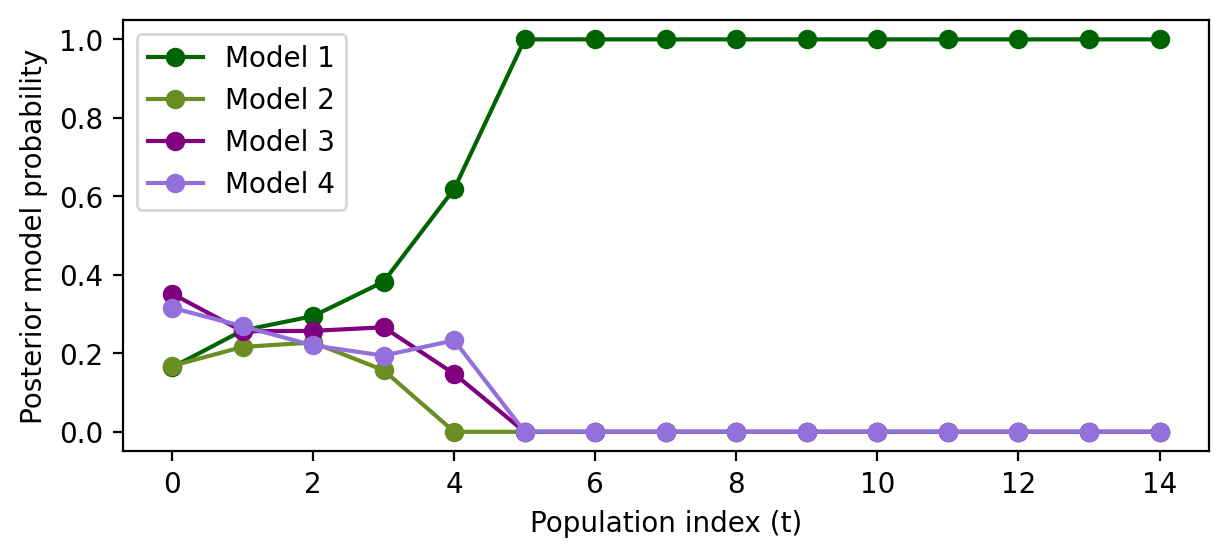

In [15]:
# Check
# Converting history data to DataFrame

db_dir = "abc_results"   # for NumStem3
# db_dir = "abc_results_2" # for NumStem10

db_file = os.path.join(db_dir, "000_000_000.db")
history = pyabc.History(f"sqlite:///{os.path.abspath(db_file)}")
df = history.get_model_probabilities()

# Plotting
plt.figure(figsize=(3.50394*2, 3.50394*0.8), dpi=200)
colordict2 = {'Model1.0':'darkgreen', 'Model2.0':'olivedrab', 'Model3.0':'purple', 'Model4.0':'mediumpurple'}

for model_id in df.columns:
    plt.plot(df.index, df[model_id], marker="o", label=f"Model {model_id+1}",color=colordict2[f"Model{model_id+1}.0"])
plt.xlabel("Population index (t)", size=10)
plt.ylabel("Posterior model probability", size=10)
plt.legend()
# plt.title("Model posterior probabilities over populations")
plt.show()

In [1]:
db_dir = "abc_results"

for para_i, para_res in enumerate(sim_data):
    for sim_i, sim_res in enumerate(para_res[1]):  # simulation results
        for sampling_i in range(5): # n_sampling in ibm_dist_sampling_func()

            db_file = os.path.join(db_dir, f"{para_i:03d}_{sim_i:03d}_{sampling_i:03d}.db")

            history = pyabc.History(f"sqlite:///{os.path.abspath(db_file)}")
            df = history.get_model_probabilities()
            
            # Plotting
            plt.figure(figsize=(3.50394*2, 3.50394*0.8), dpi=50)
            colordict2 = {
                'Model1.0':'darkgreen', 
                'Model2.0':'olivedrab', 
                'Model3.0':'purple', 
                'Model4.0':'mediumpurple'
            }
            
            for model_id in df.columns:
                plt.plot(df.index, df[model_id], marker="o", label=f"Model {model_id+1}",color=colordict2[f"Model{model_id+1}.0"])
            plt.xlabel("Population index (t)", size=10)
            plt.ylabel("Posterior model probability", size=10)
            plt.legend()
            plt.title(str(para_res[0]))
            plt.show()
            

In [2]:
db_dir = "abc_results"

for para_i, para_res in enumerate(sim_data):
    for sim_i, sim_res in enumerate(para_res[1]):  # simulation results
        
        plt.figure(figsize=(3.50394*2, 3.50394*0.8), dpi=100)
        
        for sampling_i in range(5): # n_sampling in ibm_dist_sampling_func()

            db_file = os.path.join(db_dir, f"{para_i:03d}_{sim_i:03d}_{sampling_i:03d}.db")

            history = pyabc.History(f"sqlite:///{os.path.abspath(db_file)}")
            df = history.get_model_probabilities()
            
            # Plotting
            # plt.figure(figsize=(3.50394*2, 3.50394*0.8), dpi=50)
            colordict2 = {
                'Model1.0':'darkgreen', 
                'Model2.0':'olivedrab', 
                'Model3.0':'purple', 
                'Model4.0':'mediumpurple'
            }

            if sampling_i == 0:
                for model_id in df.columns:
                    plt.plot(df.index, df[model_id], marker="o", label=f"Model {model_id+1}",color=colordict2[f"Model{model_id+1}.0"])
            else:
                for model_id in df.columns:
                    plt.plot(df.index, df[model_id], marker="o", color=colordict2[f"Model{model_id+1}.0"])
        
        plt.xlabel("Population index (t)", size=10)
        plt.ylabel("Posterior model probability", size=10)
        plt.legend()
        plt.title(str(para_res[0]))
        plt.show()    

## Apical growth model recovery rate

In [16]:
db_dir = "abc_results"

group_results = []

for para_i, para_res in enumerate(sim_data):

    true_model = int(para_res[0][6])
    true_group = "Conserved" if true_model in [1, 2] else "Replaced"

    for sim_i, sim_res in enumerate(para_res[1]):
        for sampling_i in range(5):

            db_file = os.path.join(
                db_dir,
                f"{para_i:03d}_{sim_i:03d}_{sampling_i:03d}.db"
            )

            if not os.path.exists(db_file):
                continue

            history = pyabc.History(
                f"sqlite:///{os.path.abspath(db_file)}"
            )

            # Model probabilities in the final generation
            df = history.get_model_probabilities()
            
            final_t = df.index.max()
            final_prob = df.loc[final_t].reindex([0, 1, 2, 3], fill_value=0)
            
            # Sum probabilities within each group
            p_A = final_prob[[0, 1]].sum() # Conserved apical growth
            p_B = final_prob[[2, 3]].sum() # Replaced apical growth
            
            pred_group = "Conserved" if p_A >= p_B else "Replaced"

            group_results.append({
                "para_i": para_i,
                "sim_i": sim_i,
                "sampling_i": sampling_i,
                "true_group": true_group,
                "p_C": p_A,
                "p_R": p_B,
                "pred_group": pred_group,
                "correct": pred_group == true_group
            })

group_results = pd.DataFrame(group_results)

In [17]:
# Overall accuracy

print("Overall accuracy:", group_results["correct"].mean())

# Accuracy for each true group
print(group_results.groupby("true_group")["correct"].mean())

# Confusion matrix
print(pd.crosstab(
    group_results["true_group"],
    group_results["pred_group"],
    normalize="index"
))

Overall accuracy: 0.9433333333333334
true_group
Conserved    0.973333
Replaced     0.933333
Name: correct, dtype: float64
pred_group  Conserved  Replaced
true_group                     
Conserved    0.973333  0.026667
Replaced     0.066667  0.933333


In [123]:
# Posterior prob. based accuracy

group_results["true_group_posterior"] = np.where(
    group_results["true_group"] == "Conserved",
    group_results["p_C"],
    group_results["p_R"]
)

print("Mean posterior of true group:",
      group_results["true_group_posterior"].mean())

print(group_results.groupby("true_group")[
    "true_group_posterior"
].mean())

Mean posterior of true group: 0.9434971380971274
true_group
Conserved    0.975969
Replaced     0.932673
Name: true_group_posterior, dtype: float64


In [19]:
# Parameter dependancy:
# Add true parameter values to group_results
group_results["r_"] = [
    sim_data[row.para_i][0][5]
    for row in group_results.itertuples()
]

group_results["mu_S1"] = [
    sim_data[row.para_i][0][1]
    for row in group_results.itertuples()
]

accuracy_table = group_results.pivot_table(
    index="r_",
    columns="mu_S1",
    values="correct",
    aggfunc="mean"
)

print(accuracy_table)

mu_S1  3.540000e-09  7.080000e-09  1.416000e-08
r_                                             
3              0.85          0.83         1.000
10             0.96          0.96         0.975
30             0.95          0.95         0.950


mu_S1          3.540000e-09  7.080000e-09  1.416000e-08
true_group r_                                          
Conserved  10          0.92          1.00          1.00
Replaced   3           0.85          0.83          1.00
           10          1.00          0.92          0.95
           30          0.95          0.95          0.95


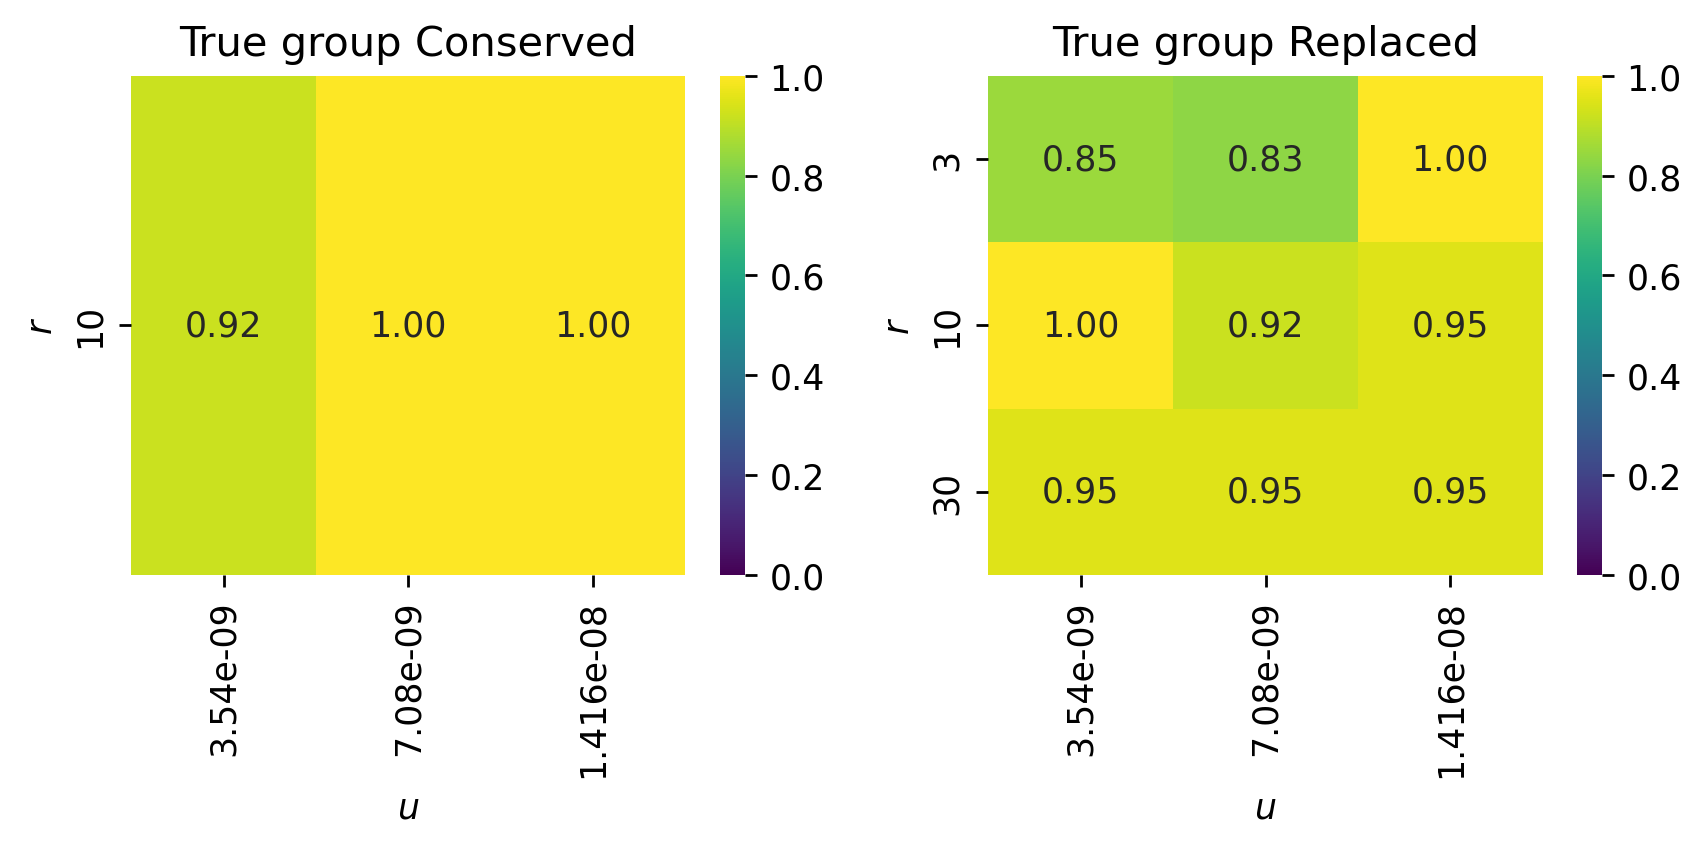

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns

# Accuracy table for each group
accuracy_table = group_results.pivot_table(
    index=["true_group", "r_"],
    columns="mu_S1",
    values="correct",
    aggfunc="mean"
)

print(accuracy_table)

# Heatmaps
# fig, axes = plt.subplots(1, 2, figsize=(3.50394*2, 3.50394), dpi=250, sharey=True)
fig, axes = plt.subplots(
    1, 2,
    figsize=(3.50394*2, 3.50394),
    dpi=250,
    sharey=False
)

for ax, group in zip(axes, ["Conserved", "Replaced"]):
    table = accuracy_table.loc[group]

    sns.heatmap(
        table,
        annot=True,
        fmt=".2f",
        vmin=0,
        vmax=1,
        cmap="viridis",
        cbar=True,
        ax=ax
    )

    ax.set_title(f"True group {group}")
    ax.set_xlabel(r"$u$")
    ax.set_ylabel(r"$r$")

plt.tight_layout()
plt.show()

### Each model recovery rate

In [126]:
model_results = []

for para_i, para_res in enumerate(sim_data):

    true_model = int(para_res[0][6])

    for sim_i, sim_res in enumerate(para_res[1]):
        for sampling_i in range(5):

            db_file = os.path.join(
                db_dir,
                f"{para_i:03d}_{sim_i:03d}_{sampling_i:03d}.db"
            )

            if not os.path.exists(db_file):
                continue

            history = pyabc.History(
                f"sqlite:///{os.path.abspath(db_file)}"
            )

            df = history.get_model_probabilities()
            final_t = df.index.max()
            final_prob = df.loc[final_t].reindex(
                [0, 1, 2, 3], fill_value=0
            )

            pred_model = int(final_prob.idxmax()) + 1

            model_results.append({
                "para_i": para_i,
                "sim_i": sim_i,
                "sampling_i": sampling_i,
                "true_model": true_model,
                "pred_model": pred_model,
                "correct": pred_model == true_model
            })

model_results = pd.DataFrame(model_results)

In [127]:
recovery_rate = model_results.groupby("true_model")["correct"].mean()

print(recovery_rate)

true_model
1    0.793333
2    0.746667
3    0.437778
4    0.440000
Name: correct, dtype: float64


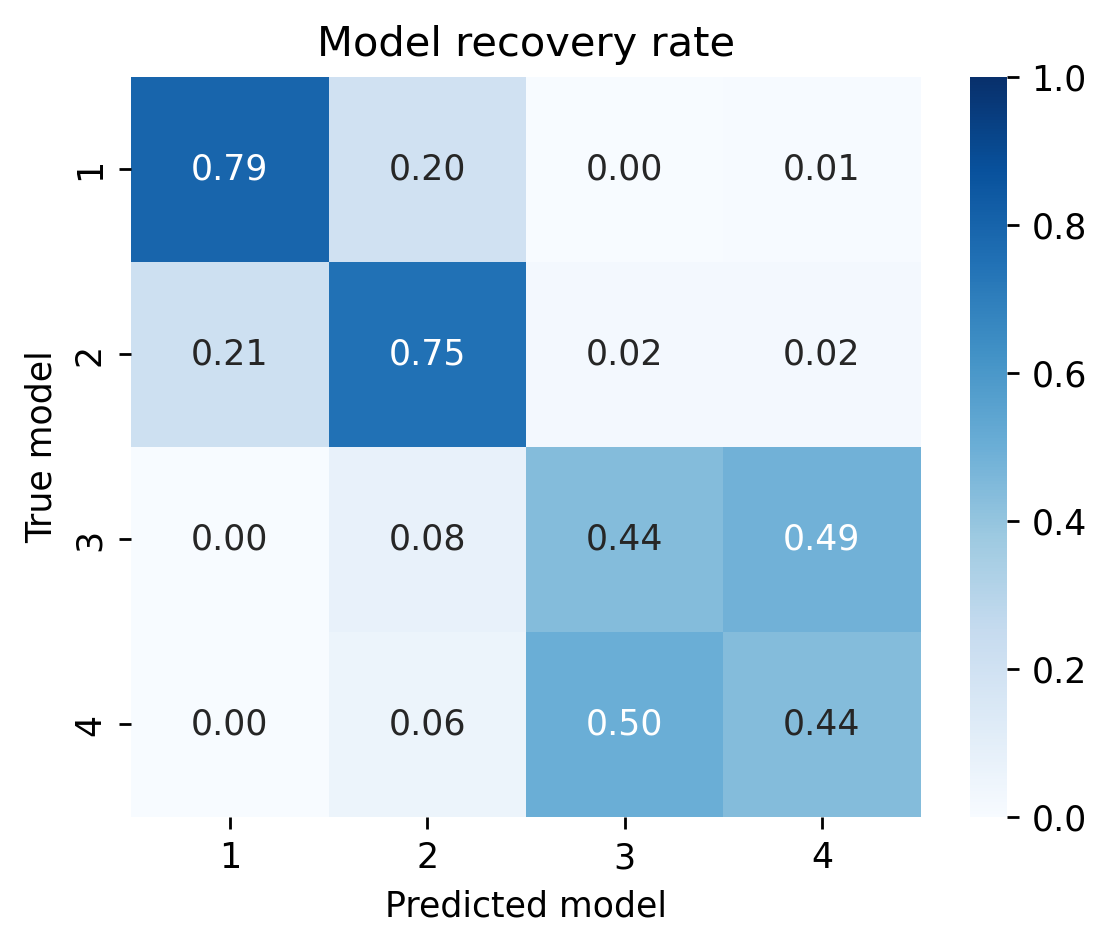

In [128]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Confusion matrix
cm = confusion_matrix(
    model_results["true_model"],
    model_results["pred_model"],
    labels=[1, 2, 3, 4],
    normalize="true"
)

# Heatmap
plt.figure(figsize=(3.50394*4/3, 3.50394*10/9), dpi=250)
sns.heatmap(
    cm,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    vmin=0,
    vmax=1,
    xticklabels=[1, 2, 3, 4],
    yticklabels=[1, 2, 3, 4]
)

plt.xlabel("Predicted model")
plt.ylabel("True model")
plt.title("Model recovery rate")
plt.tight_layout()
plt.show()

In [129]:
model_prob_results = []

for para_i, para_res in enumerate(sim_data):

    true_model = int(para_res[0][6])

    for sim_i, sim_res in enumerate(para_res[1]):
        for sampling_i in range(5):

            db_file = os.path.join(
                db_dir,
                f"{para_i:03d}_{sim_i:03d}_{sampling_i:03d}.db"
            )

            if not os.path.exists(db_file):
                continue

            history = pyabc.History(
                f"sqlite:///{os.path.abspath(db_file)}"
            )

            df = history.get_model_probabilities()
            final_t = df.index.max()

            # Keep posterior probabilities for all four models
            final_prob = df.loc[final_t].reindex(
                [0, 1, 2, 3], fill_value=0
            )

            model_prob_results.append({
                "para_i": para_i,
                "sim_i": sim_i,
                "sampling_i": sampling_i,
                "true_model": true_model,
                "P_model1": final_prob[0],
                "P_model2": final_prob[1],
                "P_model3": final_prob[2],
                "P_model4": final_prob[3],
            })

model_prob_results = pd.DataFrame(model_prob_results)

In [130]:
model_prob_results["P_true_model"] = [
    row[f"P_model{int(row['true_model'])}"]
    for _, row in model_prob_results.iterrows()
]

print("Mean posterior probability of the true model:",
      model_prob_results["P_true_model"].mean())

print(model_prob_results.groupby("true_model")[
    "P_true_model"
].mean())

Mean posterior probability of the true model: 0.5393399433595804
true_model
1    0.794556
2    0.739926
3    0.470446
4    0.456300
Name: P_true_model, dtype: float64


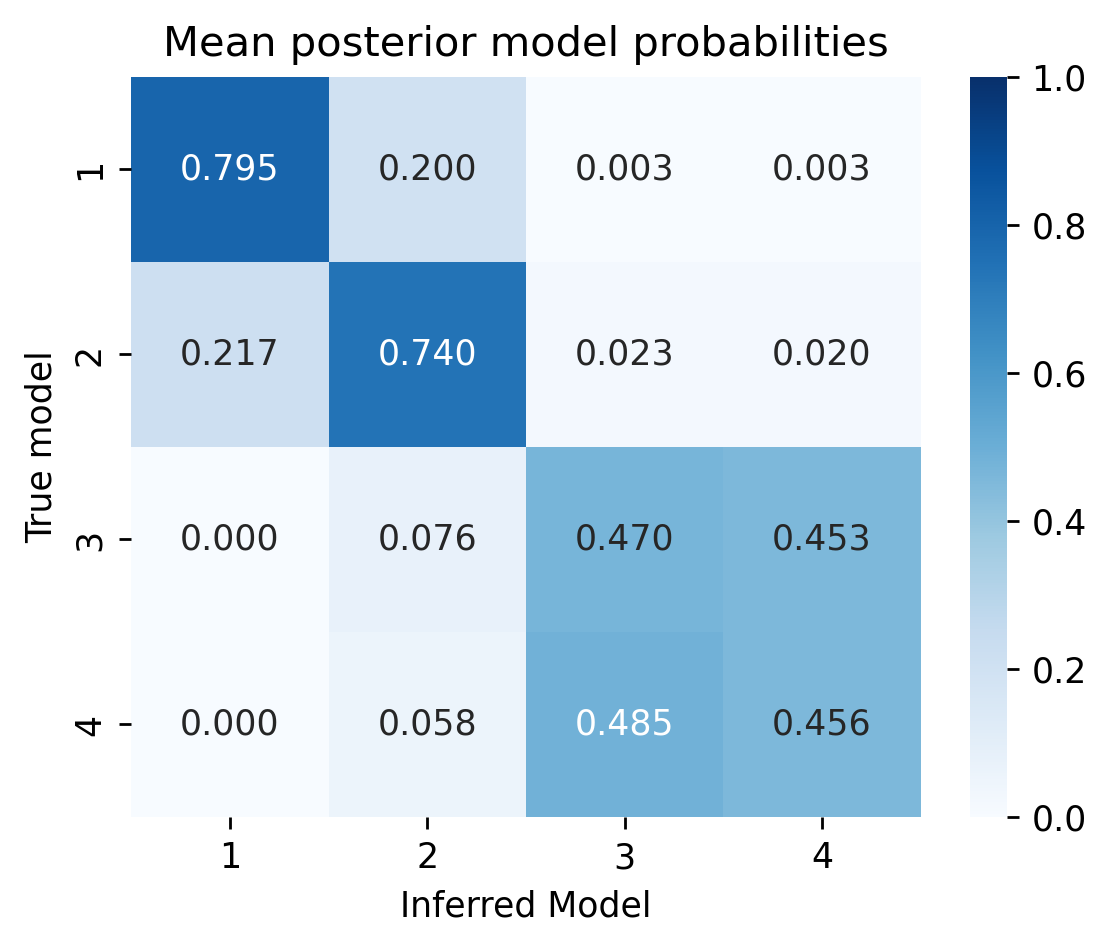

In [131]:
import matplotlib.pyplot as plt
import seaborn as sns

posterior_table = model_prob_results.groupby("true_model")[
    ["P_model1", "P_model2", "P_model3", "P_model4"]
].mean()

posterior_table.index.name = "True model"
posterior_table.columns = ["1", "2", "3", "4"]

plt.figure(figsize=(3.50394*4/3, 3.50394*10/9), dpi=250)

sns.heatmap(
    posterior_table,
    annot=True,
    fmt=".3f",
    cmap="Blues",
    vmin=0,
    vmax=1
)

plt.xlabel("Inferred Model")
plt.ylabel("True model")
plt.title("Mean posterior model probabilities")
plt.tight_layout()
plt.show()

### Parameter inference

In [3]:
db_dir = "abc_results"

for para_i, para_res in enumerate(sim_data):

    true_mu_s1 = para_res[0][1]
    true_r = para_res[0][5]
    true_model = int(para_res[0][6])
    true_model_id = true_model - 1

    posterior_data = {
        "mu_s1": [],
        "r_": []
    }

    for sim_i, sim_res in enumerate(para_res[1]):

        for sampling_i in range(5):

            db_file = os.path.join(
                db_dir,
                f"{para_i:03d}_{sim_i:03d}_{sampling_i:03d}.db"
            )

            if not os.path.exists(db_file):
                continue

            history = pyabc.History(
                f"sqlite:///{os.path.abspath(db_file)}"
            )

            # Check model recovery
            df = history.get_model_probabilities()
            final_t = df.index.max()

            final_prob = df.loc[final_t].reindex(
                [0, 1, 2, 3], fill_value=0
            )

            inferred_model_id = int(final_prob.idxmax())

            # Keep only successful model recovery
            if inferred_model_id != true_model_id:
                continue

            # Get posterior distribution
            df_post, weights = history.get_distribution(
                m=inferred_model_id,
                t=history.max_t
            )

            if len(df_post) == 0 or np.sum(weights) == 0:
                continue

            weights = np.asarray(weights, dtype=float)
            weights /= weights.sum()

            for param in ["mu_s1", "r_"]:
                posterior_data[param].append(
                    (sim_i, sampling_i,
                     df_post[param].to_numpy(), weights)
                )

    # Plot each parameter once per para_i
    for param, true_value in [
        ("mu_s1", true_mu_s1),
        ("r_", true_r)
    ]:

        if len(posterior_data[param]) == 0:
            continue

        plt.figure(
            figsize=(3.50394 * 2, 3.50394 * 0.8),
            dpi=250
        )

        for sim_i, sampling_i, values, weights in posterior_data[param]:

            plt.hist(
                values,
                bins=30,
                weights=weights,
                density=True,
                histtype="step",
                linewidth=1,
                alpha=0.7
            )

        plt.axvline(
            true_value,
            color="red",
            linestyle="--",
            linewidth=1.5
        )

        plt.xlabel(param, size=10)
        plt.ylabel("Posterior density", size=10)
        plt.title(
            f"$u$ = {para_res[0][1]}, $r$ = {para_res[0][5]}, Model {true_model}: "
            f"{len(posterior_data[param])} successful fits"
        )

        plt.tight_layout()
        plt.show()

In [29]:
def weighted_quantile(values, weights, quantiles):
    sort_idx = np.argsort(values)
    values = np.asarray(values)[sort_idx]
    weights = np.asarray(weights)[sort_idx]

    cumulative_weights = np.cumsum(weights)
    cumulative_weights /= cumulative_weights[-1]

    return np.interp(
        quantiles,
        cumulative_weights,
        values
    )

import pandas as pd
import numpy as np
import os
import pyabc

db_dir = "abc_results"

recovery_data = []

for para_i, para_res in enumerate(sim_data):

    true_mu_s1 = para_res[0][1]
    true_r = para_res[0][5]
    true_model = int(para_res[0][6])
    true_model_id = true_model - 1

    for sim_i, sim_res in enumerate(para_res[1]):

        for sampling_i in range(5):

            db_file = os.path.join(
                db_dir,
                f"{para_i:03d}_{sim_i:03d}_{sampling_i:03d}.db"
            )

            if not os.path.exists(db_file):
                continue

            history = pyabc.History(
                f"sqlite:///{os.path.abspath(db_file)}"
            )

            # Check model recovery
            df = history.get_model_probabilities()
            final_t = df.index.max()

            final_prob = df.loc[final_t].reindex(
                [0, 1, 2, 3], fill_value=0
            )

            inferred_model_id = int(final_prob.idxmax())

            # Keep only successful model recovery
            if inferred_model_id != true_model_id:
                continue

            # Get posterior distribution
            df_post, weights = history.get_distribution(
                m=inferred_model_id,
                t=history.max_t
            )

            if len(df_post) == 0:
                continue

            weights = np.asarray(weights, dtype=float)

            if not np.all(np.isfinite(weights)) or weights.sum() <= 0:
                continue

            weights /= weights.sum()

            for param, true_value in [
                ("mu_s1", true_mu_s1),
                ("r_", true_r)
            ]:

                values = df_post[param].to_numpy()

                # Remove invalid values
                valid = np.isfinite(values) & np.isfinite(weights)
                values = values[valid]
                param_weights = weights[valid]

                if len(values) == 0 or param_weights.sum() <= 0:
                    continue

                param_weights /= param_weights.sum()

                # Posterior median and 95% credible interval
                lower, median, upper = weighted_quantile(
                    values,
                    param_weights,
                    [0.025, 0.5, 0.975]
                )

                recovery_data.append({
                    "para_i": para_i,
                    "sim_i": sim_i,
                    "sampling_i": sampling_i,
                    "true_model": true_model,
                    "param": param,
                    "true_value": true_value,
                    "median": median,
                    "lower": lower,
                    "upper": upper,
                    "covered": lower <= true_value <= upper,
                    "values": values,
                    "weights": param_weights
                })

recovery_df = pd.DataFrame(recovery_data)

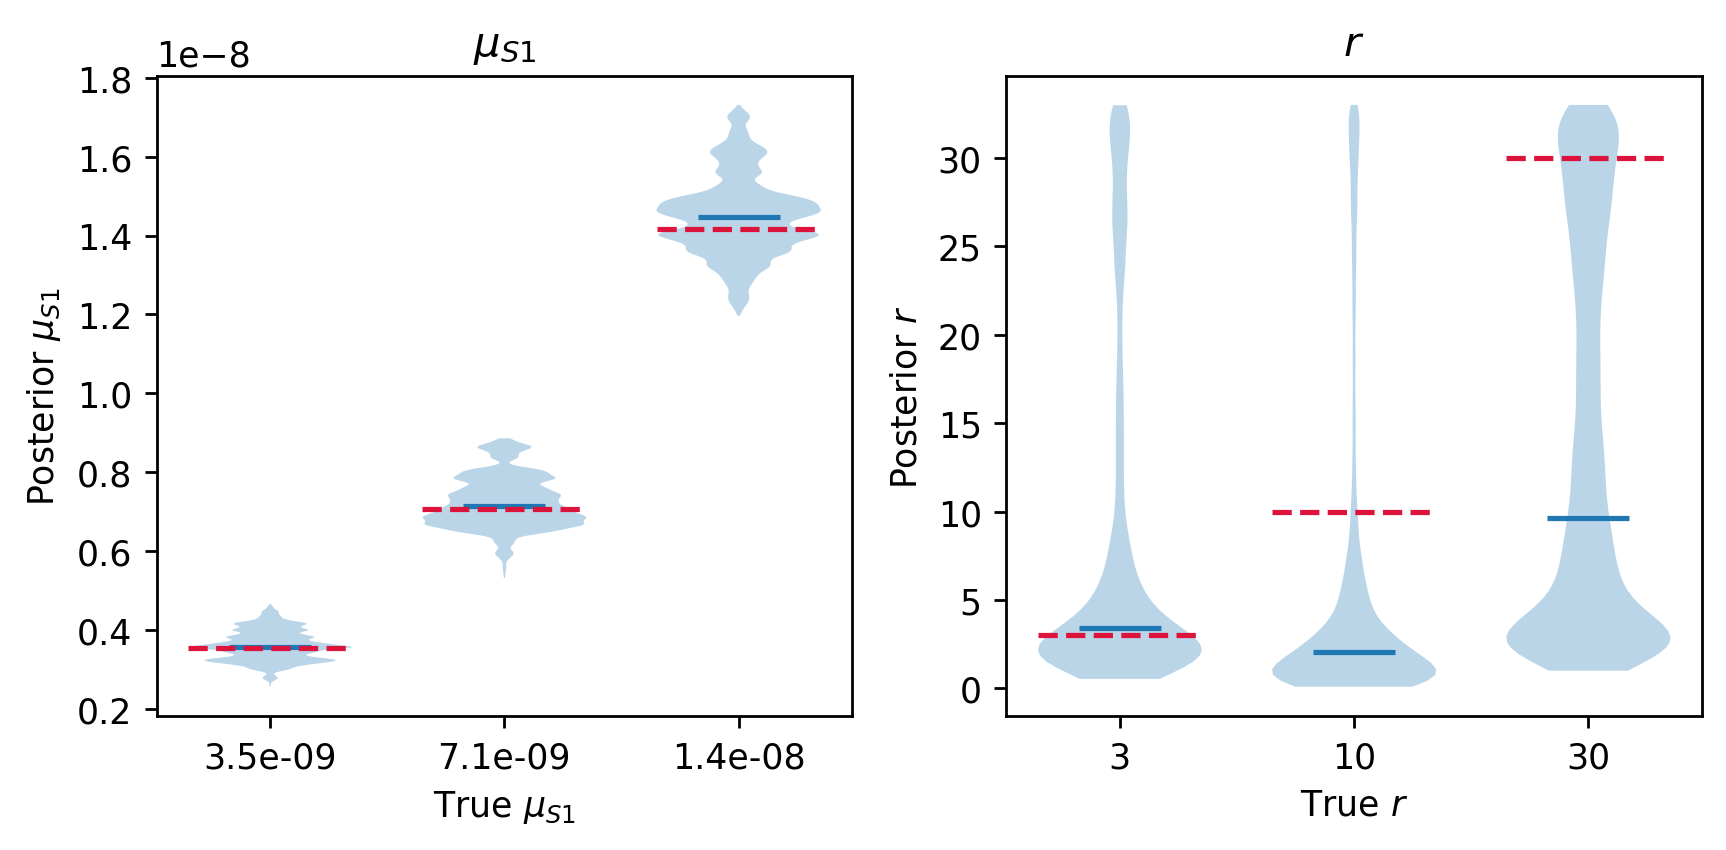

In [46]:
import numpy as np
import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    1, 2,
    figsize=(3.50394 * 2, 3.50394),
    dpi=250
)

for ax, param, label in zip(
    axes,
    ["mu_s1", "r_"],
    [r"$\mu_{S1}$", r"$r$"]
):

    data = recovery_df[
        recovery_df["param"] == param
    ]

    # Group by true parameter value
    grouped_data = data.groupby("true_value")

    positions = []
    distributions = []

    rng = np.random.default_rng(42)

    for true_value, group in grouped_data:

        # Pool posterior samples, giving each fitting equal contribution
        pooled_samples = []

        for _, row in group.iterrows():

            values = np.asarray(row["values"])
            weights = np.asarray(row["weights"], dtype=float)

            weights /= weights.sum()

            # Weighted resampling
            samples = rng.choice(
                values,
                size=500,
                replace=True,
                p=weights
            )

            pooled_samples.extend(samples)

        positions.append(true_value)
        distributions.append(np.asarray(pooled_samples))

    # Violin plot
    parts = ax.violinplot(
        distributions,
        positions=np.arange(len(positions)),
        widths=0.7,
        showmedians=True,
        showextrema=False
    )

    # True parameter values
    for i, true_value in enumerate(positions):
        ax.hlines(
            true_value,
            i - 0.35,
            i + 0.35,
            color="crimson",
            linestyle="--",
            linewidth=1.5
        )

    # ax.set_yscale("log")

    ax.set_xticks(np.arange(len(positions)))
    ax.set_xticklabels([
        f"{v:.2g}" for v in positions
    ])

    ax.set_xlabel(f"True {label}")
    ax.set_ylabel(f"Posterior {label}")
    ax.set_title(label)

plt.tight_layout()
plt.show()